# Model v0.7: structure, mechanisms, response, scorecard and roadmap

Each cell calls one function in `avalanche_research.views`. The memo's images are saved states of these same plots, drawn by `scripts/figures/model_story_figures.py`. Runs: `staking-periods-2026-09-30`, staking periods accepted before the validation lockbox only.

In [1]:
from datetime import UTC, date, datetime

import holoviews as hv
from IPython.display import SVG

from avalanche_research import datasets
from avalanche_research.mechanisms.cohort import group_stakes, load_periods
from avalanche_research.views import model_results as mr
from avalanche_research.views.model_structure import lifecycle_dot, render

hv.extension("bokeh")
RUN = "staking-periods-2026-09-30"
PERIODS = str(datasets.parquet_path("derived.staking-periods", RUN))
SUPPLY_NAVAX = 465_373_500 * 10**9
PRICED_AT = datetime(2026, 12, 22, tzinfo=UTC)

## The model's structure, traced from its code

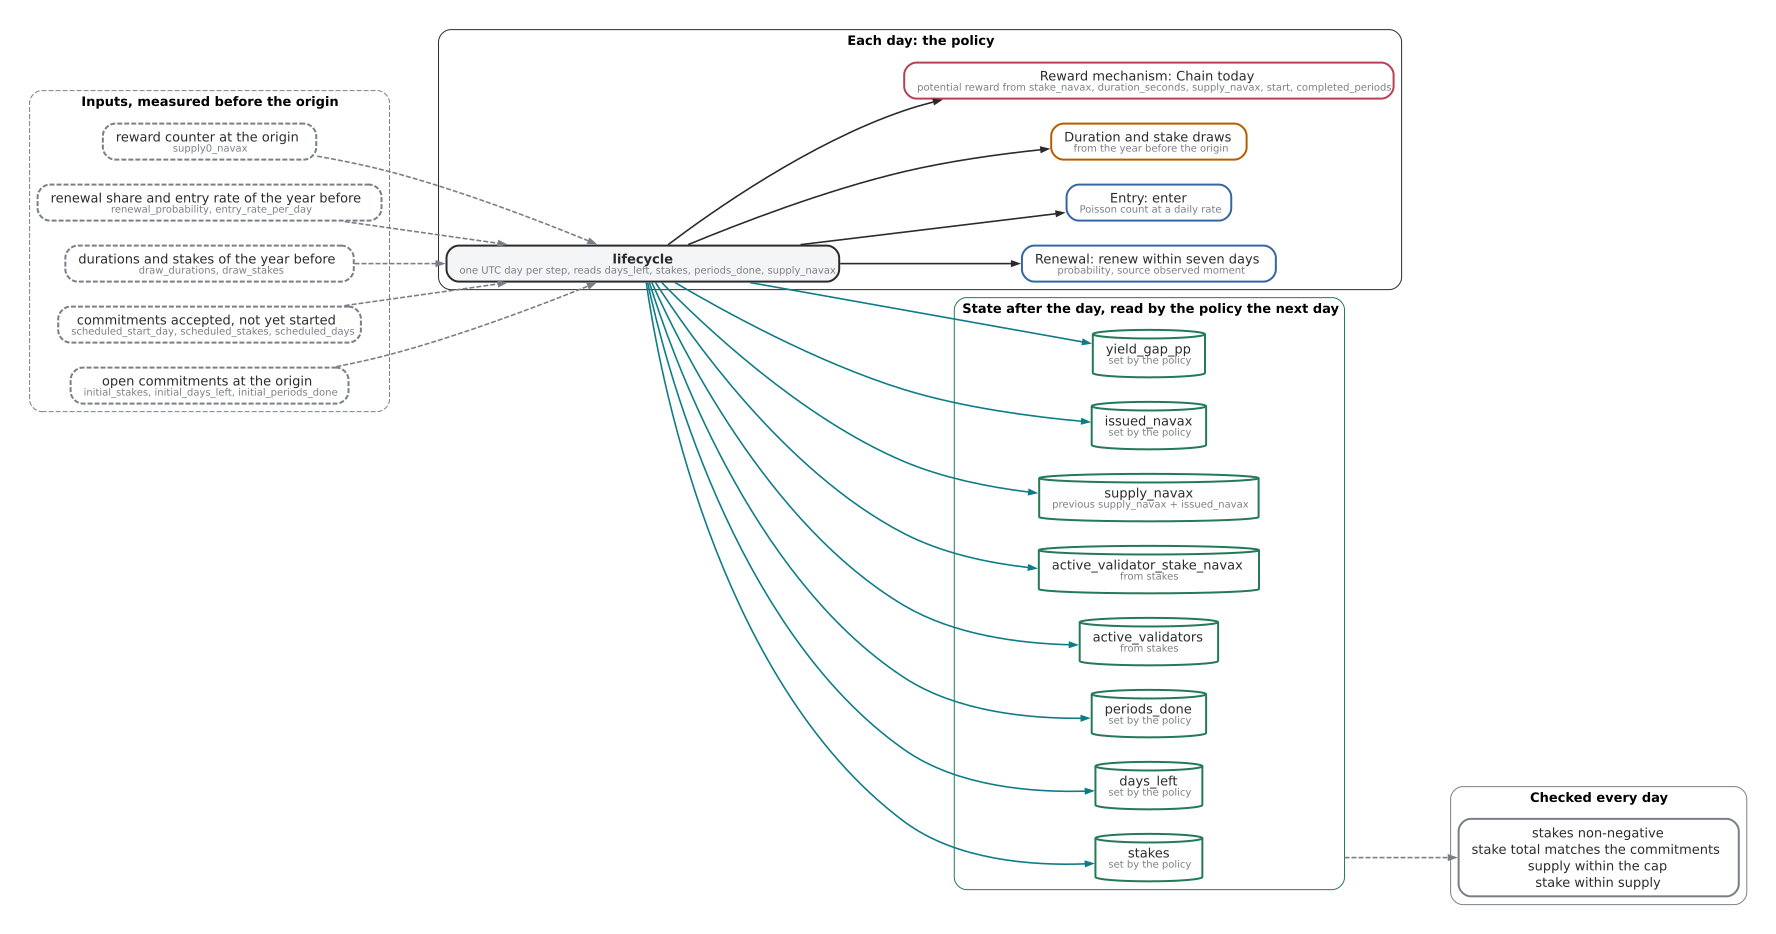

In [2]:
from pathlib import Path
import tempfile

stem = Path(tempfile.mkdtemp()) / "model-structure"
render(lifecycle_dot(), stem)
SVG(filename=str(stem.with_suffix(".svg")))

## Reward designs: rate by duration, and AVAX minted for the reference cohort

In [3]:
cohort = group_stakes(load_periods(PERIODS))
mechanisms = mr.reference_mechanisms(cohort, SUPPLY_NAVAX, PRICED_AT)
mr.mechanism_plot(mr.mechanism_table(mechanisms, SUPPLY_NAVAX, PRICED_AT), mr.reference_issuance(mechanisms, cohort, SUPPLY_NAVAX, PRICED_AT))

:Layout
   .Overlay.I  :Overlay
      .Curve.Chain_today                                       :Curve   [weeks]   (annual_rate_pct,mechanism)
      .Curve.ACP_hyphen_minus_285_settings                     :Curve   [weeks]   (annual_rate_pct,mechanism)
      .Curve.Tenure_boost                                      :Curve   [weeks]   (annual_rate_pct,mechanism)
      .Curve.Quadratic_curve                                   :Curve   [weeks]   (annual_rate_pct,mechanism)
      .Curve.Quadratic_curve_comma_today_apostrophe_s_issuance :Curve   [weeks]   (annual_rate_pct,mechanism)
   .Overlay.II :Overlay
      .Bars.I   :Bars   [mechanism]   (issuance_million_avax,change)
      .Labels.I :Labels   [x,y]   (change)

## Validators after 180 days against AVAX issued, at three response strengths, from Fortuna

In [4]:
mr.sweep_plot(mr.response_sweep(PERIODS))

/home/shawn/Workspace/BCRG/Avalanche-Phase-II/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



                  ___________    ____
  ________ __ ___/ / ____/   |  / __ \
 / ___/ __` / __  / /   / /| | / / / /
/ /__/ /_/ / /_/ / /___/ ___ |/ /_/ /
\___/\__,_/\__,_/\____/_/  |_/_____/
by cadCAD

cadCAD Version: 0.5.3
Execution Mode: local_proc
Simulation Dimensions:
Entire Simulation: (Models, Unique Timesteps, Params, Total Runs, Sub-States) = (5, 900, 55, 100, 8)
     Simulation 0: (Timesteps, Params, Runs, Sub-States) = (180, 11, 20, 8)
     Simulation 1: (Timesteps, Params, Runs, Sub-States) = (180, 11, 20, 8)
     Simulation 2: (Timesteps, Params, Runs, Sub-States) = (180, 11, 20, 8)
     Simulation 3: (Timesteps, Params, Runs, Sub-States) = (180, 11, 20, 8)
     Simulation 4: (Timesteps, Params, Runs, Sub-States) = (180, 11, 20, 8)


Initializing configurations:   0%|          | 0/100 [00:00<?, ?it/s]

Initializing configurations:  42%|████▏     | 42/100 [00:00<00:00, 418.69it/s]

Initializing configurations:  87%|████████▋ | 87/100 [00:00<00:00, 435.20it/s]

...

Flattening results:  37%|███▋      | 37/100 [00:00<00:00, 362.13it/s]

Flattening results:  78%|███████▊  | 78/100 [00:00<00:00, 389.41it/s]

Flattening results: 100%|██████████| 100/100 [00:00<00:00, 377.38it/s]

Total execution time: 7.99s


:Layout
   .Overlay.I   :Overlay
      .ErrorBars.I                                               :ErrorBars   [x]   (y,yerrneg,yerrpos)
      .Scatter.Chain_today                                       :Scatter   [issuance_million_avax]   (validators_mean,mechanism)
      .ErrorBars.II                                              :ErrorBars   [x]   (y,yerrneg,yerrpos)
      .Scatter.ACP_hyphen_minus_285_settings                     :Scatter   [issuance_million_avax]   (validators_mean,mechanism)
      .ErrorBars.III                                             :ErrorBars   [x]   (y,yerrneg,yerrpos)
      .Scatter.Tenure_boost                                      :Scatter   [issuance_million_avax]   (validators_mean,mechanism)
      .ErrorBars.IV                                              :ErrorBars   [x]   (y,yerrneg,yerrpos)
      .Scatter.Quadratic_curve                                   :Scatter   [issuance_million_avax]   (validators_mean,mechanism)
      .ErrorBars.V                                               :ErrorBars   [x]   (y,yerrneg,yerrpos)
      .Scatter.Quadratic_curve_comma_today_apostrophe_s_issuance :Scatter   [issuance_million_avax]   (validators_mean,mechanism)
   .Overlay.II  :Overlay
      .ErrorBars.I                                               :ErrorBars   [x]   (y,yerrneg,yerrpos)
      .Scatter.Chain_today                                       :Scatter   [issuance_million_avax]   (validators_mean,mechanism)
      .ErrorBars.II                                              :ErrorBars   [x]   (y,yerrneg,yerrpos)
      .Scatter.ACP_hyphen_minus_285_settings                     :Scatter   [issuance_million_avax]   (validators_mean,mechanism)
      .ErrorBars.III                                             :ErrorBars   [x]   (y,yerrneg,yerrpos)
      .Scatter.Tenure_boost                                      :Scatter   [issuance_million_avax]   (validators_mean,mechanism)
      .ErrorBars.IV                                              :ErrorBars   [x]   (y,yerrneg,yerrpos)
      .Scatter.Quadratic_curve                                   :Scatter   [issuance_million_avax]   (validators_mean,mechanism)
      .ErrorBars.V                                               :ErrorBars   [x]   (y,yerrneg,yerrpos)
      .Scatter.Quadratic_curve_comma_today_apostrophe_s_issuance :Scatter   [issuance_million_avax]   (validators_mean,mechanism)
   .Overlay.III :Overlay
      .ErrorBars.I                                               :ErrorBars   [x]   (y,yerrneg,yerrpos)
      .Scatter.Chain_today                                       :Scatter   [issuance_million_avax]   (validators_mean,mechanism)
      .ErrorBars.II                                              :ErrorBars   [x]   (y,yerrneg,yerrpos)
      .Scatter.ACP_hyphen_minus_285_settings                     :Scatter   [issuance_million_avax]   (validators_mean,mechanism)
      .ErrorBars.III                                             :ErrorBars   [x]   (y,yerrneg,yerrpos)
      .Scatter.Tenure_boost                                      :Scatter   [issuance_million_avax]   (validators_mean,mechanism)
      .ErrorBars.IV                                              :ErrorBars   [x]   (y,yerrneg,yerrpos)
      .Scatter.Quadratic_curve                                   :Scatter   [issuance_million_avax]   (validators_mean,mechanism)
      .ErrorBars.V                                               :ErrorBars   [x]   (y,yerrneg,yerrpos)
      .Scatter.Quadratic_curve_comma_today_apostrophe_s_issuance :Scatter   [issuance_million_avax]   (validators_mean,mechanism)

## The lifecycle model against holding the origin value, at five upgrades

In [5]:
scores = mr.lifecycle_scores(PERIODS)
mr.score_plot(scores)


                  ___________    ____
  ________ __ ___/ / ____/   |  / __ \
 / ___/ __` / __  / /   / /| | / / / /
/ /__/ /_/ / /_/ / /___/ ___ |/ /_/ /
\___/\__,_/\__,_/\____/_/  |_/_____/
by cadCAD

cadCAD Version: 0.5.3
Execution Mode: single_proc
Simulation Dimensions:
Entire Simulation: (Models, Unique Timesteps, Params, Total Runs, Sub-States) = (1, 90, 11, 20, 8)
     Simulation 0: (Timesteps, Params, Runs, Sub-States) = (90, 11, 20, 8)


Initializing configurations:   0%|          | 0/20 [00:00<?, ?it/s]

Initializing configurations: 100%|██████████| 20/20 [00:00<00:00, 326.59it/s]

Execution Method: single_proc_exec


Flattening results:   0%|          | 0/3620 [00:00<?, ?it/s]

...

Execution Method: single_proc_exec


Flattening results:   0%|          | 0/3620 [00:00<?, ?it/s]

Flattening results:   1%|          | 20/3620 [00:00<00:08, 402.43it/s]

Total execution time: 0.68s


:Layout
   .Overlay.I  :Overlay
      .Segments.I                          :Segments   [x0,y0,x1,y1]
      .Scatter.Holding_the_origin_value    :Scatter   [hold_pct]   (y,row)
      .Scatter.Model_comma_mean_of_20_runs :Scatter   [model_pct]   (y,row)
      .Scatter.Band_covers_actual          :Scatter   [x]   (y)
      .Scatter.Band_misses_actual          :Scatter   [x]   (y)
   .Overlay.II :Overlay
      .Segments.I                          :Segments   [x0,y0,x1,y1]
      .Scatter.Holding_the_origin_value    :Scatter   [hold_pct]   (y,row)
      .Scatter.Model_comma_mean_of_20_runs :Scatter   [model_pct]   (y,row)
      .Scatter.Band_covers_actual          :Scatter   [x]   (y)
      .Scatter.Band_misses_actual          :Scatter   [x]   (y)

## The model's versions by the call that shows each one

In [6]:
mr.roadmap_plot(today=date(2026, 10, 1))

:Overlay
   .Segments.I :Segments   [x0,y0,x1,y1]
   .VLine.I    :VLine   [x,y]
   .Text.I     :Text   [x,y]
   .VLine.II   :VLine   [x,y]
   .Text.II    :Text   [x,y]
   .VLine.III  :VLine   [x,y]
   .Text.III   :Text   [x,y]
   .VLine.IV   :VLine   [x,y]
   .Text.IV    :Text   [x,y]
   .VLine.V    :VLine   [x,y]
   .Scatter.I  :Scatter   [call]   (y,version,capability)
   .Scatter.II :Scatter   [call]   (y,version,capability)
   .Labels.I   :Labels   [x,y]   (text)